# 실패를 처리하는 라우팅

**이 노트북에서 할 일**

1. 모델이 쓴 문의 종류를 보고, 코드가 준비한 갈래 가운데 하나로 보냅니다.
2. 종류가 허용 목록에 있는지, 신뢰도가 기준값 이상인지 검사하는 함수를 만듭니다.
3. 검사 없이 종류 이름을 믿으면 흐름이 멈추거나 엉뚱한 갈래로 가는 것을 봅니다(Before).
4. 검사를 지나지 못한 문의를 되묻기 갈래로 보냅니다(After).

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 노트북 한 번에 여덟 번입니다.
3절에서 한 번, 7절에서 세 번, 8절에서 네 번 나갑니다.

토큰 수를 출력하는 요청은 여덟 번 가운데 네 번입니다.
나머지 요청도 같은 크기로 보고 요금표를 곱해 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01절에서 배운 함수 둘은 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 20초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
분류 요청과 갈래 표, 검사 함수를 익히는 자리입니다.
7~9절은 검사 없는 라우팅과 검사하는 라우팅을 이어 실행하는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 요청 머리글과 고객 문의에서 보라 상자 gpt-5.4-mini 분류 요청으로, 다시 노란 상자 분류 딕셔너리 칸 둘 종류와 신뢰도로, 다시 파란 상자 검사 check_route 허용 목록과 기준값 0.75로 이어지고, 검사에서 점선 둘이 나뉘어 문제 없음이면 보라 상자 gpt-5.4-mini 갈래 표에서 고른 지시 글로 답 요청을 지나 노란 상자 상태 완료 답으로 가고 문제 있음이면 노란 상자 상태 되묻기 되묻기 글 답 요청 없음으로 가는 그림](attachment:02-1-종류를-보고-갈래로.png)

위에서 아래로 읽습니다. 초록 문의가 보라 분류 요청을 지나 노란 분류 딕셔너리가 됩니다.
파란 검사에서 점선이 둘로 나뉩니다. 문제가 없을 때만 보라 답 요청으로 가고, 문제가 있으면 노란 되묻기로 갑니다.
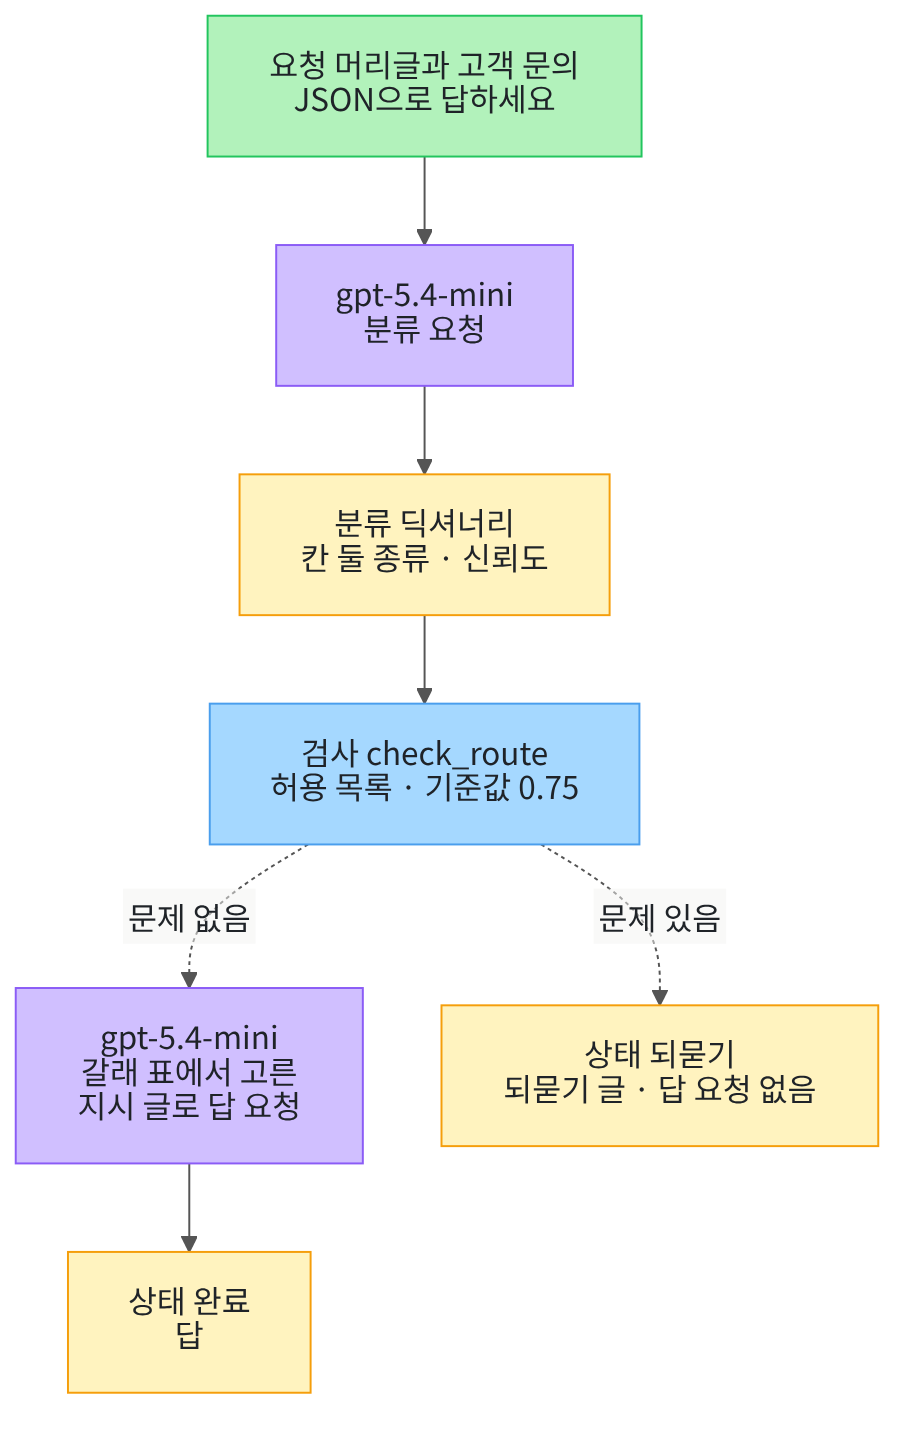

## 1. 준비

제목의 라우팅(routing)은 Ch 17 01절에서 정한 말입니다.
모델이 쓴 종류 이름을 보고, 코드가 준비한 갈래 가운데 하나로 가는 모양입니다.
Ch 17 01절은 모델이 썼다고 정한 종류 이름을 손으로 넣어 코드 쪽 갈래만 보았고, 이 절은 실제 모델이 종류를 씁니다.

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 클라이언트 이름과, 01절에서 배운 함수 둘을 가져옵니다.

In [2]:
# 클라이언트 이름 OpenAI와, 01절에서 배운 함수 둘을 도구 파일 workflow_tools.py에서 가져옵니다
from openai import OpenAI

from workflow_tools import ask_json, print_records

print("불러온 이름:", "OpenAI", "ask_json", "print_records")

불러온 이름: OpenAI ask_json print_records


**결과 읽기** — 출력 줄 `불러온 이름: OpenAI ask_json print_records`로 이름 셋을 가져왔습니다.
함수 `ask_json`은 요청 한 번을 보내 기록 한 줄을 남기고, 받은 JSON 글을 딕셔너리로 내놓습니다.
함수 `print_records`는 기록 목록을 번호·단계·입력 토큰·출력 토큰 차례로 출력합니다.
두 함수는 01절 노트북에서 정의한 함수와 코드가 같습니다.

## 2. 키와 클라이언트 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.
클라이언트는 서비스에 요청을 보내고 응답을 받는 파이썬 객체입니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
이 노트북의 모든 요청은 이 클라이언트 하나로 보냅니다.

## 3. 문의 종류를 쓰게 하는 분류 요청

라우팅의 첫 단계는 분류입니다.
분류 요청은 모델에게 문의의 종류 이름과 신뢰도를 JSON 글로 쓰게 합니다.
종류는 결제·계정·기술 가운데 하나이고, 하나로 정할 수 없으면 「모름」으로 쓰게 합니다.
신뢰도(confidence)는 모델이 자기가 쓴 종류가 맞다고 스스로 적는 0~1 사이 수입니다.
재서 얻은 값이 아니라 모델이 쓴 글의 일부입니다.

In [5]:
# 분류 단계의 지시 글을 적습니다: 종류 셋과, 하나로 정할 수 없을 때 쓸 이름 「모름」
classify_instructions = "고객 문의를 종류 하나로 가르는 분류 담당입니다. "
classify_instructions = classify_instructions + "종류는 결제, 계정, 기술 가운데 하나로 적습니다. "
classify_instructions = classify_instructions + "하나로 정할 수 없으면 종류를 모름으로 적습니다. "
# 신뢰도는 모델이 스스로 적는 수입니다(재서 얻은 값이 아님)
classify_instructions = classify_instructions + "신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. "
classify_instructions = classify_instructions + '답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}'
print("분류 지시 글:")
print(classify_instructions)

분류 지시 글:
고객 문의를 종류 하나로 가르는 분류 담당입니다. 종류는 결제, 계정, 기술 가운데 하나로 적습니다. 하나로 정할 수 없으면 종류를 모름으로 적습니다. 신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. 답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}


**결과 읽기** — 라벨 줄 `분류 지시 글:` 아래 한 줄이 분류 단계의 지시 글입니다.
끝에 답 모양 `{"종류": "글", "신뢰도": 수}`를 적어 두었습니다.

다음 셀은 요청 글을 만듭니다.
01절의 형식 `json_object`는 JSON으로 답하라는 말이 글에 있어야 합니다.
노트북 밖에서 먼저 보내 보니, 서비스는 그 말을 지시 글이 아니라 요청 글에서 찾았습니다.
지시 글에만 그 말을 두자 서비스가 오류(400)로 요청을 막았습니다.
그래서 요청 글 앞에 JSON이라는 말이 든 머리글 한 줄을 붙입니다.

In [6]:
# 두 단계가 함께 쓸 요청 머리글을 적고, 결제 문의 하나로 요청 글을 만듭니다
# 형식 json_object는 요청 글에 JSON이라는 말이 있어야 해서 머리글에 적어 둡니다
request_head = "아래 고객 문의에 JSON으로 답하세요.\n문의: "
billing_question = "카드에서 같은 요금이 두 번 결제됐어요."
billing_request = request_head + billing_question
print("요청 글:")
print(billing_request)

요청 글:
아래 고객 문의에 JSON으로 답하세요.
문의: 카드에서 같은 요금이 두 번 결제됐어요.


**결과 읽기** — 라벨 줄 `요청 글:` 아래 두 줄이 분류 요청 글입니다.
첫 줄이 요청 머리글이고, 줄 `문의:` 뒤가 결제 문의입니다.
뒤에서 보낼 답 요청에도 같은 요청 글을 씁니다.

다음 셀은 이 요청 글로 분류 요청을 한 번 보냅니다.
01절에서 만든 함수 `ask_json`에 단계 이름 「분류」를 넣어 부릅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [7]:
# 분류 요청을 01절 함수 ask_json으로 한 번 보내 분류 딕셔너리를 받습니다(모델 요청 1번)
records = []
billing_decision = ask_json(client, records, "분류", classify_instructions, billing_request)
print("분류:", billing_decision)
print("종류:", billing_decision["종류"])
print("신뢰도:", billing_decision["신뢰도"])
print_records(records)

분류: {'종류': '결제', '신뢰도': 0.99}
종류: 결제
신뢰도: 0.99
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 분류 | 126 | 22


**결과 읽기** — 출력 줄 `종류: 결제`로 모델이 결제 문의를 종류 「결제」로 썼습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 줄 `1 | 분류 | 126 | 22`가 이 요청의 기록입니다.

출력 줄 `신뢰도:` 뒤 수는 모델이 스스로 적은 수라 실행마다 달라질 수 있습니다.
교재 출력에서는 `신뢰도: 0.99`였습니다.

## 4. 갈래 표

갈래(branch)는 종류마다 준비해 둔 다음 처리입니다.
이 절의 갈래는 종류마다 다른 지시 글로 답을 쓰게 하는 요청입니다.
갈래 표는 종류 이름을 칸 이름으로, 그 갈래의 지시 글을 값으로 둔 딕셔너리입니다.

In [8]:
# 종류마다 준비한 갈래의 지시 글을 갈래 표(딕셔너리) 하나에 모읍니다
# 세 지시 글의 뒷부분(답 모양)은 같아서 한 번만 적어 붙입니다
answer_tail = ' 한국어 두 문장으로 답하고, 답은 JSON 객체 하나로만 출력합니다: {"답": "글"}'
branch_table = {
    "결제": "결제 문의를 맡은 상담원입니다." + answer_tail,
    "계정": "계정 문의를 맡은 상담원입니다." + answer_tail,
    "기술": "기술 문의를 맡은 상담원입니다." + answer_tail,
}
print("갈래 수:", len(branch_table))

갈래 수: 3


**결과 읽기** — 출력 줄 `갈래 수: 3`으로 갈래 셋을 준비했습니다.
「모름」 칸은 두지 않았습니다. 모름에 맞는 상담원을 준비하지 않았기 때문입니다.

다음 셀은 3절 분류의 종류 이름으로 갈래 표에서 지시 글을 찾습니다.
딕셔너리에서 대괄호에 키를 넣어 값을 찾는 모양은 Ch 2 03절에서 배웠습니다.
이 셀은 모델을 부르지 않습니다.

In [9]:
# 3절 분류의 종류 이름으로 갈래 표에서 지시 글을 찾습니다(모델 요청 없음)
billing_branch = branch_table[billing_decision["종류"]]
print("찾은 갈래의 지시 글:")
print(billing_branch)

찾은 갈래의 지시 글:
결제 문의를 맡은 상담원입니다. 한국어 두 문장으로 답하고, 답은 JSON 객체 하나로만 출력합니다: {"답": "글"}


**결과 읽기** — 라벨 줄 `찾은 갈래의 지시 글:` 아래가 결제 갈래의 지시 글입니다.
첫 문장 「결제 문의를 맡은 상담원입니다.」가 이 갈래의 역할입니다.
모델은 종류 이름만 썼고, 어느 지시 글로 갈지는 코드가 표에서 골랐습니다.

## 5. 허용 목록과 기준값 검사

갈래 표에서 찾기 전에 분류를 검사합니다.
허용 목록은 갈래로 보내도 되는 종류 이름의 목록입니다.
Ch 16 01절의 출처 표시 허용 목록처럼, 목록 밖 값은 다음 단계로 넘기지 않습니다.
기준값(threshold)은 신뢰도를 견줄 수입니다.
Ch 13 03절에서 점수를 기준값과 견줘 갈래를 고른 것과 같은 자리입니다.

In [10]:
# 갈래로 보내도 되는 종류 목록(허용 목록)과, 신뢰도를 견줄 기준값을 정합니다
# 허용 목록은 갈래 표의 칸 이름으로 만들어 갈래가 없는 종류가 끼지 않게 합니다
allowed_kinds = list(branch_table.keys())
threshold = 0.75
print("허용 목록:", allowed_kinds)
print("기준값:", threshold)

허용 목록: ['결제', '계정', '기술']
기준값: 0.75


**결과 읽기** — 출력 줄 `허용 목록: ['결제', '계정', '기술']`은 갈래 표의 칸 이름 목록입니다.
갈래 표에서 만들었으므로 갈래가 없는 종류는 목록에도 없습니다.
출력 줄 `기준값: 0.75`는 흐름을 보여 주려고 정한 값이고, 라벨이 있는 자료로 고르지 않았습니다.

다음 셀은 분류를 검사하는 함수입니다.
01절 게이트 `check_plan`처럼 문제를 글 목록으로 내놓고, 문제가 없으면 빈 목록을 내놓습니다.

In [11]:
# 분류를 검사해 갈래로 보내면 안 되는 까닭을 글 목록으로 내놓습니다(문제가 없으면 빈 목록)
def check_route(decision, allowed_kinds, threshold):
    problems = []
    # 모델이 쓴 종류가 허용 목록에 없으면 문제입니다
    if decision["종류"] not in allowed_kinds:
        problems.append("허용 목록에 없는 종류")
    # 모델이 스스로 적은 신뢰도가 기준값보다 낮아도 문제입니다
    if decision["신뢰도"] < threshold:
        problems.append("신뢰도가 기준값보다 낮음")
    return problems

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_route`는 분류 딕셔너리와 허용 목록, 기준값을 받습니다.
먼저 칸 「종류」의 값이 허용 목록에 없는지 `not in`으로 봅니다.
그다음 칸 「신뢰도」의 값이 기준값보다 작은지 봅니다.
두 검사는 따로 보므로 문제가 둘 다 나올 수도 있습니다.

다음 셀은 손으로 적은 분류 셋으로 검사 함수를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [12]:
# 손으로 적은 분류 셋으로 검사를 확인합니다(모델 글이 아니라 정해 둔 값이라 assert로 봅니다)
known_sample = {"종류": "결제", "신뢰도": 0.9}
unknown_sample = {"종류": "모름", "신뢰도": 0.9}
low_sample = {"종류": "기술", "신뢰도": 0.4}
print("아는 종류·높은 신뢰도:", check_route(known_sample, allowed_kinds, threshold))
print("모르는 종류:", check_route(unknown_sample, allowed_kinds, threshold))
print("낮은 신뢰도:", check_route(low_sample, allowed_kinds, threshold))
assert check_route(unknown_sample, allowed_kinds, threshold) == ["허용 목록에 없는 종류"]
assert check_route(low_sample, allowed_kinds, threshold) == ["신뢰도가 기준값보다 낮음"]

아는 종류·높은 신뢰도: []
모르는 종류: ['허용 목록에 없는 종류']
낮은 신뢰도: ['신뢰도가 기준값보다 낮음']


**결과 읽기** — 출력 줄 `아는 종류·높은 신뢰도: []`는 빈 목록이라 통과입니다.
출력 줄 `모르는 종류: ['허용 목록에 없는 종류']`는 신뢰도가 높아도 종류에서 걸렸습니다.
출력 줄 `낮은 신뢰도: ['신뢰도가 기준값보다 낮음']`은 종류는 목록 안이지만 신뢰도에서 걸렸습니다.
마지막 두 줄의 `assert`도 통과했습니다.

다음 셀은 3절에서 모델이 쓴 분류에 같은 검사를 겁니다.

In [13]:
# 3절에서 모델이 쓴 분류에도 같은 검사를 걸어 봅니다(모델 요청 없음)
billing_problems = check_route(billing_decision, allowed_kinds, threshold)
print("결제 문의 분류의 문제:", billing_problems)
print("문제 수:", len(billing_problems))

결제 문의 분류의 문제: []
문제 수: 0


**결과 읽기** — 출력 줄 `결제 문의 분류의 문제: []`와 `문제 수: 0`으로 3절 분류는 검사를 지납니다.
종류 「결제」가 허용 목록에 있고, 신뢰도가 기준값보다 낮지 않기 때문입니다.

## 6. 되묻기 갈래와 흐름 설정

되묻기(clarification)는 검사를 지나지 못한 문의에 답하지 않고, 고객에게 내용을 더 묻는 갈래입니다.
이 갈래는 모델을 부르지 않고, 미리 적어 둔 글을 내놓습니다.

In [14]:
# 검사를 지나지 못한 문의에 보낼 되묻기 글을 적습니다(이 갈래는 모델을 부르지 않습니다)
ask_back_text = "문의 내용을 조금 더 알려 주세요. 결제, 계정, 기술 가운데 어느 문제인지도 함께 적어 주세요."
print("되묻기 글:", ask_back_text)

되묻기 글: 문의 내용을 조금 더 알려 주세요. 결제, 계정, 기술 가운데 어느 문제인지도 함께 적어 주세요.


**결과 읽기** — 출력 줄 `되묻기 글:` 뒤가 고객에게 보낼 글입니다.
세 종류 이름을 함께 적어, 고객이 다시 쓸 때 종류가 드러나게 했습니다.

다음 셀은 라우팅 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다.
01절 흐름 설정처럼, 흐름 함수는 이 딕셔너리 하나를 받아 값을 꺼내 씁니다.

In [15]:
# 라우팅 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다
route_setup = {
    "분류 지시 글": classify_instructions,
    "요청 머리글": request_head,
    "갈래 표": branch_table,
    "허용 목록": allowed_kinds,
    "기준값": threshold,
    "되묻기 글": ask_back_text,
}
setup_keys = list(route_setup.keys())
print("설정 칸:", setup_keys)

설정 칸: ['분류 지시 글', '요청 머리글', '갈래 표', '허용 목록', '기준값', '되묻기 글']


**결과 읽기** — 출력 줄 `설정 칸: ['분류 지시 글', '요청 머리글', '갈래 표', '허용 목록', '기준값', '되묻기 글']`로 여섯 칸을 모았습니다.

## 7. 검사 없는 라우팅 (Before)

Before 흐름은 모델이 쓴 종류 이름을 검사하지 않고 곧바로 갈래 표에서 찾습니다.
여기에 문의 둘을 넣습니다.
하나는 로그인과 카드 청구가 섞인 문의이고, 하나는 준비한 갈래가 없는 배송 문의입니다.
두 문의는 8절 After 흐름에도 그대로 넣습니다.

In [16]:
# Before와 After에 함께 넣을 문의 둘: 두 문제가 섞인 문의와, 준비한 갈래가 없는 배송 문의입니다
mixed_question = "로그인도 안 되고 카드 청구도 이상해요."
delivery_question = "주문한 물건이 아직 안 왔어요."
print("섞인 문의:", mixed_question)
print("배송 문의:", delivery_question)

섞인 문의: 로그인도 안 되고 카드 청구도 이상해요.
배송 문의: 주문한 물건이 아직 안 왔어요.


**결과 읽기** — 출력 줄 `섞인 문의:`와 `배송 문의:` 뒤가 두 문의입니다.
섞인 문의는 계정과 결제 두 종류에 걸칩니다.
배송 문의는 결제·계정·기술 어디에도 딱 맞지 않습니다.

다음 셀은 검사 없는 라우팅 함수입니다.

In [17]:
# 검사 없는 라우팅: 모델이 쓴 종류 이름을 그대로 갈래 표에서 찾아 답합니다(모델 요청 1~2번)
def route_without_check(client, records, setup, question):
    request_text = setup["요청 머리글"] + question
    decision = ask_json(client, records, "분류", setup["분류 지시 글"], request_text)
    branch_instructions = setup["갈래 표"][decision["종류"]]
    written = ask_json(client, records, "답", branch_instructions, request_text)
    return {"상태": "완료", "분류": decision, "문제": [], "답": written["답"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `route_without_check`는 분류 요청을 보내고, 모델이 쓴 종류 이름으로 곧바로 갈래 표를 찾습니다.
그 갈래의 지시 글로 답 요청을 보내고 상태 `완료`를 내놓습니다.
분류를 보는 곳이 없어 칸 「문제」는 늘 빈 목록입니다.

다음 셀은 섞인 문의를 이 흐름에 넣습니다.
Ch 2 03절에서 배운 대로, 딕셔너리에 없는 키를 대괄호로 읽으면 파이썬은 `KeyError`를 냅니다.
이 셀은 Ch 2 05절의 `try`와 `except KeyError as error`로 그 오류만 받아 이름을 출력합니다.
흐름 함수 안에는 받는 곳이 없으므로, 실제 프로그램이라면 여기서 멈춥니다.

In [18]:
# 섞인 문의를 검사 없는 흐름에 넣습니다(모델 요청 1번 뒤 오류가 납니다)
before_mixed_records = []
# 이 셀만 그 오류 이름을 받아 출력합니다(흐름 함수 안에는 받는 곳이 없습니다)
try:
    before_mixed = route_without_check(client, before_mixed_records, route_setup, mixed_question)
    before_mixed_state = before_mixed["상태"]
except KeyError as error:
    before_mixed_state = type(error).__name__
    print("받은 오류:", before_mixed_state, error)
print("요청 수(기록 줄 수):", len(before_mixed_records))
print_records(before_mixed_records)

받은 오류: KeyError '모름'
요청 수(기록 줄 수): 1
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 분류 | 125 | 22


**결과 읽기** — 출력 줄 `받은 오류: KeyError '모름'`이 이 흐름의 첫 결함입니다.
모델이 종류 「모름」을 썼고, 갈래 표에 그 칸이 없어 표를 찾는 줄에서 오류가 났습니다.
출력 줄 `요청 수(기록 줄 수): 1`로 분류 요청만 나가고 답 요청 전에 멈췄습니다.
라벨 줄 아래 한 줄 `1 | 분류 | 125 | 22`가 그 분류 요청의 기록입니다.

셀이 오류를 받지 않았다면 이 자리에서 노트북 실행이 끝났을 것입니다.
다음 셀은 배송 문의를 같은 흐름에 넣습니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [19]:
# 배송 문의를 검사 없는 흐름에 넣습니다(모델 요청 2번)
before_delivery_records = []
before_delivery = route_without_check(client, before_delivery_records, route_setup, delivery_question)
print("상태:", before_delivery["상태"])
print("흐름이 알린 문제:", before_delivery["문제"])
print("요청 수(기록 줄 수):", len(before_delivery_records))
print("모델이 쓴 종류:", before_delivery["분류"]["종류"])
print("그 갈래의 지시 글로 받은 답:")
print(before_delivery["답"])

상태: 완료
흐름이 알린 문제: []
요청 수(기록 줄 수): 2
모델이 쓴 종류: 결제
그 갈래의 지시 글로 받은 답:
불편을 드려 죄송합니다. 주문번호를 알려주시면 배송 상태를 바로 확인해드리겠습니다.


**결과 읽기** — 출력 줄 `상태: 완료`와 `흐름이 알린 문제: []`가 이 흐름이 알려 준 전부입니다.
출력 줄 `요청 수(기록 줄 수): 2`로 답 요청까지 나갔습니다.
모델이 쓴 종류가 허용 목록 안의 이름이라 오류 없이 그 갈래로 갔습니다.

출력 줄 `모델이 쓴 종류:` 뒤 이름과 답 글은 실행마다 달라질 수 있습니다.
교재 출력에서는 `모델이 쓴 종류: 결제`였고, 결제 갈래의 지시 글로 답을 받았습니다.
이 절은 답 내용이 맞는지 판정하지 않았습니다.

다음 셀은 흐름이 끝난 뒤에야 같은 검사 규칙으로, 갈래로 넘어간 분류를 검사합니다.

In [20]:
# 흐름이 끝난 뒤에야 같은 검사 규칙으로, 갈래로 넘어간 분류를 검사합니다(모델 요청 없음)
late_problems = check_route(before_delivery["분류"], allowed_kinds, threshold)
print("넘어간 분류의 문제:", late_problems)
print("넘어간 분류의 신뢰도:", before_delivery["분류"]["신뢰도"])
print("기준값:", threshold)

넘어간 분류의 문제: ['신뢰도가 기준값보다 낮음']
넘어간 분류의 신뢰도: 0.34
기준값: 0.75


**결과 읽기** — 출력 줄 `넘어간 분류의 문제: ['신뢰도가 기준값보다 낮음']`이 이 흐름의 둘째 결함입니다.
모델이 스스로 적은 신뢰도가 출력 줄 `기준값: 0.75`보다 낮았는데도 갈래로 보냈습니다.
그런데도 흐름은 앞 셀에서 상태 `완료`를 알렸습니다.

출력 줄 `넘어간 분류의 신뢰도:` 뒤 수는 실행마다 달라질 수 있습니다.
교재 출력에서는 `넘어간 분류의 신뢰도: 0.34`였습니다.

## 8. 검사하는 라우팅 (After)

After 흐름은 분류와 답 요청 사이에 5절 검사 함수를 둡니다.
검사가 문제를 하나라도 찾으면 답 요청을 보내지 않고 되묻기 갈래로 갑니다.
그때는 상태 `되묻기`와 문제 목록, 되묻기 글을 내놓습니다.

In [21]:
# 라우팅: 분류를 검사해 문제가 있으면 되묻기 갈래로, 없으면 그 종류의 갈래로 답합니다(모델 요청 1~2번)
def route_question(client, records, setup, question):
    request_text = setup["요청 머리글"] + question
    decision = ask_json(client, records, "분류", setup["분류 지시 글"], request_text)
    problems = check_route(decision, setup["허용 목록"], setup["기준값"])
    # 문제가 하나라도 있으면 갈래 표를 찾기 전에 되묻기 갈래로 끝냅니다(답 요청 없음)
    if len(problems) > 0:
        return {"상태": "되묻기", "분류": decision, "문제": problems, "답": setup["되묻기 글"]}
    branch_instructions = setup["갈래 표"][decision["종류"]]
    written = ask_json(client, records, "답", branch_instructions, request_text)
    return {"상태": "완료", "분류": decision, "문제": problems, "답": written["답"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `route_question`은 Before 함수의 분류와 갈래 찾기 사이에 검사 세 줄을 넣었습니다.
분류를 받은 뒤 `check_route`로 검사하고, 문제가 있으면 `return`으로 바로 끝냅니다.
그래서 모르는 종류로 갈래 표를 찾는 줄에는 닿지 않습니다.
마지막 줄의 칸 「문제」에는 빈 목록 대신 검사 결과를 넣습니다.

다음 셀은 7절과 같은 섞인 문의를 이 흐름에 넣습니다.

In [22]:
# 같은 섞인 문의를 검사하는 흐름에 넣습니다(모델 요청 1번 — 답 요청은 나가지 않습니다)
after_mixed_records = []
after_mixed = route_question(client, after_mixed_records, route_setup, mixed_question)
print("상태:", after_mixed["상태"])
print("검사가 찾은 문제:", after_mixed["문제"])
print("모델이 쓴 종류:", after_mixed["분류"]["종류"])
print("요청 수(기록 줄 수):", len(after_mixed_records))
print("고객에게 보낼 글:", after_mixed["답"])

상태: 되묻기
검사가 찾은 문제: ['허용 목록에 없는 종류']
모델이 쓴 종류: 모름
요청 수(기록 줄 수): 1
고객에게 보낼 글: 문의 내용을 조금 더 알려 주세요. 결제, 계정, 기술 가운데 어느 문제인지도 함께 적어 주세요.


**결과 읽기** — 출력 줄 `상태: 되묻기`로 흐름이 되묻기 갈래로 갔습니다.
출력 줄 `검사가 찾은 문제: ['허용 목록에 없는 종류']`와 `모델이 쓴 종류: 모름`이 까닭입니다.
출력 줄 `요청 수(기록 줄 수): 1`로 답 요청은 나가지 않았습니다.
출력 줄 `고객에게 보낼 글:` 뒤가 6절에서 적은 되묻기 글입니다.

다음 셀은 같은 배송 문의를 이 흐름에 넣습니다.

In [23]:
# 같은 배송 문의를 검사하는 흐름에 넣습니다(모델 요청 1번 — 답 요청은 나가지 않습니다)
after_delivery_records = []
after_delivery = route_question(client, after_delivery_records, route_setup, delivery_question)
print("상태:", after_delivery["상태"])
print("검사가 찾은 문제:", after_delivery["문제"])
print("모델이 쓴 종류:", after_delivery["분류"]["종류"])
print("요청 수(기록 줄 수):", len(after_delivery_records))
print("고객에게 보낼 글:", after_delivery["답"])

상태: 되묻기
검사가 찾은 문제: ['신뢰도가 기준값보다 낮음']
모델이 쓴 종류: 결제
요청 수(기록 줄 수): 1
고객에게 보낼 글: 문의 내용을 조금 더 알려 주세요. 결제, 계정, 기술 가운데 어느 문제인지도 함께 적어 주세요.


**결과 읽기** — 출력 줄 `상태: 되묻기`로 배송 문의도 되묻기 갈래로 갔습니다.
출력 줄 `검사가 찾은 문제: ['신뢰도가 기준값보다 낮음']`이 까닭입니다.
출력 줄 `요청 수(기록 줄 수): 1`로 답 요청은 나가지 않았습니다.

출력 줄 `모델이 쓴 종류:` 뒤 이름은 실행마다 달라질 수 있습니다.
교재 출력에서는 `모델이 쓴 종류: 결제`였습니다.
7절과 8절은 분류 요청을 따로 보냈으므로 두 분류가 서로 다를 수 있습니다.

다음 셀은 두 문의를 두 흐름에 넣은 결과를 한 표로 나란히 봅니다.

In [24]:
# 두 문의를 두 흐름에 넣은 결과와 요청 수를 한 표로 봅니다
print("문의 | 검사 없는 흐름 | 요청 수 | 검사하는 흐름 | 요청 수")
print("섞인 문의 |", before_mixed_state, "|", len(before_mixed_records), "|", after_mixed["상태"], "|", len(after_mixed_records))
print("배송 문의 |", before_delivery["상태"], "|", len(before_delivery_records), "|", after_delivery["상태"], "|", len(after_delivery_records))

문의 | 검사 없는 흐름 | 요청 수 | 검사하는 흐름 | 요청 수
섞인 문의 | KeyError | 1 | 되묻기 | 1
배송 문의 | 완료 | 2 | 되묻기 | 1


**결과 읽기** — 라벨 줄 `문의 | 검사 없는 흐름 | 요청 수 | 검사하는 흐름 | 요청 수` 아래 두 줄이 두 문의입니다.
줄 `섞인 문의 | KeyError | 1 | 되묻기 | 1`은 요청 수는 같지만 끝이 다릅니다.
검사 없는 흐름은 오류로 멈췄고, 검사하는 흐름은 되묻기 글을 내놓고 끝났습니다.
줄 `배송 문의 | 완료 | 2 | 되묻기 | 1`은 검사 없는 흐름만 답 요청을 한 번 더 보냈습니다.

다음 셀은 결제 문의를 검사하는 흐름에 넣습니다.
검사를 지나는 문의는 전처럼 그 종류의 갈래로 가는지 봅니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [25]:
# 결제 문의를 검사하는 흐름에 넣습니다(모델 요청 2번 — 검사를 지나 결제 갈래로 답합니다)
billing_records = []
billing_result = route_question(client, billing_records, route_setup, billing_question)
print("상태:", billing_result["상태"])
print("검사가 찾은 문제:", billing_result["문제"])
print("모델이 쓴 종류:", billing_result["분류"]["종류"])
print_records(billing_records)
print("답:")
print(billing_result["답"])

상태: 완료
검사가 찾은 문제: []
모델이 쓴 종류: 결제
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 분류 | 126 | 22
2 | 답 | 70 | 57
답:
불편을 드려 죄송합니다. 결제 내역과 중복 승인 여부를 확인해드릴 수 있도록 카드사명, 결제일시, 금액을 알려주시면 바로 확인하겠습니다.


**결과 읽기** — 출력 줄 `상태: 완료`와 `검사가 찾은 문제: []`로 결제 문의는 검사를 지났습니다.
출력 줄 `모델이 쓴 종류: 결제`로 코드가 결제 갈래의 지시 글을 골랐습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 첫 줄 `1 | 분류 | 126 | 22`가 분류 요청, 둘째 줄이 답 요청의 기록입니다.

라벨 줄 `답:` 아래 글과 둘째 기록 줄의 출력 토큰은 실행마다 달라질 수 있습니다.
교재 출력에서는 둘째 줄이 `2 | 답 | 70 | 57`이었습니다.
이 절은 답 내용이 맞는지 판정하지 않았습니다.

## 9. 값 바꿔 보기 · 허용 목록에서 종류 하나를 빼면

바꿀 값은 허용 목록 하나입니다.
결제 갈래를 잠시 닫는다고 보고, 「결제」를 뺀 목록으로 8절 결제 문의의 분류를 다시 검사합니다.
이 셀은 모델을 부르지 않습니다.

실행 전에 예상해 봅니다.
모델이 쓴 종류는 그대로 「결제」이니, 바꾼 목록에서는 허용 목록에 없는 종류라는 문제가 나올 것입니다.

In [26]:
# 바꿀 값은 허용 목록 하나입니다: 「결제」를 뺀 목록으로 8절 결제 문의의 분류를 다시 검사합니다(모델 요청 없음)
narrow_kinds = ["계정", "기술"]
old_problems = check_route(billing_result["분류"], allowed_kinds, threshold)
new_problems = check_route(billing_result["분류"], narrow_kinds, threshold)
print("바꾼 허용 목록:", narrow_kinds)
print("원래 목록의 문제:", old_problems)
print("바꾼 목록의 문제:", new_problems)

바꾼 허용 목록: ['계정', '기술']
원래 목록의 문제: []
바꾼 목록의 문제: ['허용 목록에 없는 종류']


**결과 읽기** — 출력 줄 `바꾼 허용 목록: ['계정', '기술']`이 바꾼 목록입니다.
출력 줄 `원래 목록의 문제: []`와 `바꾼 목록의 문제: ['허용 목록에 없는 종류']`가 두 목록의 결과입니다.
예상대로 같은 분류가 바꾼 목록에서는 막힙니다.

이 목록을 설정에 넣고 흐름을 다시 실행하지는 않았습니다.
그래도 함수 `route_question`은 문제 목록이 비지 않으면 답 요청 전에 되묻기로 끝나도록 적혀 있습니다.
모델이 같은 종류를 써도, 어느 갈래를 열지는 코드가 쥔 목록이 정합니다.

## 정리

1. 모델은 문의 종류와 신뢰도를 JSON 글로 쓰고, 코드는 그 종류로 갈래 표에서 갈래를 골랐습니다.
2. 검사 없는 흐름은 모르는 종류에서 `KeyError`로 멈췄고, 신뢰도가 낮은 분류도 갈래로 보냈습니다.
3. 검사하는 흐름은 같은 두 문의를 되묻기 갈래로 보냈고, 결제 문의는 결제 갈래로 답했습니다.

03절에서는 서로 기다릴 필요가 없는 모델 요청 여러 개를 함께 보내고 결과를 모읍니다.